<a href="https://colab.research.google.com/github/varunrm/New-York-ML-project/blob/main/NYC_Taxi_Tip_Model_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Tipping Behavior in NYC Yellow Taxi Trips
### Deliverable 2: Model Optimization, Real-World Impact, and Ethical Evaluation (Refined Version)

**Team:** Faisal Ahmed, Varun Reddy Muddasani, Vishal Reddy Shyamala
**Course:** PhDAI-733-M21, University of the Cumberlands
**Code repository:** [https://github.com/varunrm/New-York-ML-project](https://github.com/varunrm/New-York-ML-project)

**Recap of Deliverable 1.** Using a 10% sample of January 2016 NYC yellow-taxi trips (Kaggle elemento/nyc-yellow-taxi-trip-data), we predicted whether a credit-card trip receives a tip of **at least 20%** of the pre-tip charge. The best initial model (Random Forest) reached ROC-AUC = 0.580. The first Deliverable 2 version, which added location cells and tuning, reached only 0.586.

**What changed in this refined version**
1. **More training data.** A 20% sample of January (about 1.4 million card trips) instead of 10%; the learning curve shows the model still improves with more data.
2. **Wider tuning** with early stopping for gradient boosting, feature subsampling, and larger trees.
3. **No class weighting.** The decision threshold handles the 70/30 imbalance instead, so predicted probabilities are calibrated (much lower Brier score).
4. **Bill-rounding features.** Riders who type a custom tip often round the total up to the next $1, $5 or $10, so the distance of the bill from a round number was tested as a predictor.
5. **A leakage check.** Computing the bill as total_amount - tip_amount leaves tiny floating-point traces of the tip, which inflates ROC-AUC to about 0.73. The bill is therefore rebuilt from its parts and rounded to cents (Section 4 demonstrates the leak).
6. A **feature ablation** and **learning curve** that show where the gains come from.

The evaluation, out-of-time check (February 2016), fairness audit and lift analysis are the same as before.

## 1. Setup and Imports

In [ ]:
# Install kagglehub with pandas support (only needed in Google Colab)
import sys, subprocess
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub[pandas-datasets]'], check=False)

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix, balanced_accuracy_score,
                             classification_report, roc_curve, precision_recall_curve)
from scipy.stats import loguniform

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)

FIG_DIR = 'figures_d2'
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

COLORS = {'Logistic Regression': '#4C72B0', 'Random Forest': '#55A868',
          'Hist Gradient Boosting': '#C44E52', 'D1 Random Forest': '#8C8C8C'}

## 2. Data Loading

Same source as Deliverable 1. January 2016 is now sampled at **20%** (seed 42) instead of 10%, because the learning-curve check in Section 4 shows the model keeps improving with more data. A separate 5% sample of **February 2016** is loaded as an *out-of-time* test set, to check whether the model still works on a month it never saw.

*Colab note:* kagglehub downloads each monthly file once (about 1.7 GB each); loading takes a few minutes and uses about 3 GB of RAM, which fits the free tier.

*Scaling note (Dask, optional):* the full month (10.9M rows) can be processed with dask.dataframe.read_csv; set RUN_DASK = True in the optional cell below to try it.

In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

def load_month(file_path, frac, seed):
    rng = np.random.default_rng(seed)
    return kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "elemento/nyc-yellow-taxi-trip-data",
        file_path,
        pandas_kwargs={
            "skiprows": lambda i: i > 0 and rng.random() > frac,
            "parse_dates": ["tpep_pickup_datetime", "tpep_dropoff_datetime"],
        },
    )

start = time.time()
jan_raw = load_month("yellow_tripdata_2016-01.csv", frac=0.20, seed=RANDOM_STATE)   # 20% sample
feb_raw = load_month("yellow_tripdata_2016-02.csv", frac=0.05, seed=7)
print(f"Loaded in {time.time() - start:.0f} s")
print("January sample:", jan_raw.shape, "| February sample:", feb_raw.shape)
print("First 5 records:", jan_raw.head())

NameError: name 'time' is not defined

In [ ]:
# Optional: Dask over the full January file (about 10.9 million rows)
RUN_DASK = False
if RUN_DASK:
    import dask.dataframe as dd
    path = kagglehub.dataset_download("elemento/nyc-yellow-taxi-trip-data", path="yellow_tripdata_2016-01.csv")
    ddf = dd.read_csv(path, usecols=['payment_type', 'tip_amount', 'total_amount'])
    card = ddf[ddf.payment_type == 1]
    rate = (card.tip_amount / (card.total_amount - card.tip_amount) >= 0.195).mean().compute()
    print(f"Full-month share of card trips tipping 20%+: {rate:.3f}")
else:
    print("Dask step skipped (set RUN_DASK = True to run on the full month).")

Dask step skipped (set RUN_DASK = True to run on the full month).


## 3. Cleaning and Feature Engineering

In [ ]:
PAYMENT_CARD = 1
LAT, LON = (40.49, 40.92), (-74.27, -73.68)
JFK = (40.6413, -73.7781); LGA = (40.7769, -73.8740)

def near(lat, lon, pt, r=0.02):
    return ((lat - pt[0])**2 + (lon - pt[1])**2) < r**2

def prepare(raw):
    df = raw.drop_duplicates().dropna().copy()
    df['trip_minutes'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60
    df['avg_speed_mph'] = df['trip_distance'] / (df['trip_minutes'] / 60)
    keep = (df['trip_minutes'].between(1, 180) & df['trip_distance'].between(0.1, 100) &
            df['fare_amount'].between(2.5, 500) & df['passenger_count'].between(1, 6) &
            df['RatecodeID'].isin([1, 2, 3, 4, 5, 6]) &
            df['pickup_latitude'].between(*LAT) & df['pickup_longitude'].between(*LON) &
            df['dropoff_latitude'].between(*LAT) & df['dropoff_longitude'].between(*LON) &
            (df['avg_speed_mph'] <= 80))
    df = df[keep & (df['payment_type'] == PAYMENT_CARD)].copy()

    # Target: tip of 20% or more of the pre-tip charge (0.5-point tolerance for cent rounding)
    df['pre_tip_total'] = df['total_amount'] - df['tip_amount']
    df['tip_rate'] = df['tip_amount'] / df['pre_tip_total']
    df['high_tip'] = (df['tip_rate'] >= 0.195).astype(int)

    # Deliverable 1 features
    t = df['tpep_pickup_datetime']
    df['pickup_hour'] = t.dt.hour
    df['pickup_dow'] = t.dt.dayofweek
    df['is_weekend'] = (df['pickup_dow'] >= 5).astype(int)
    df['hour_sin'] = np.sin(2 * np.pi * df['pickup_hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['pickup_hour'] / 24)
    df['airport_trip'] = (df['RatecodeID'].isin([2, 3]) |
        near(df['pickup_latitude'], df['pickup_longitude'], JFK) | near(df['pickup_latitude'], df['pickup_longitude'], LGA) |
        near(df['dropoff_latitude'], df['dropoff_longitude'], JFK) | near(df['dropoff_latitude'], df['dropoff_longitude'], LGA)).astype(int)
    df['manhattan_pickup'] = (df['pickup_latitude'].between(40.70, 40.80) &
                              df['pickup_longitude'].between(-74.02, -73.93)).astype(int)

    # Deliverable 2 features
    df['rush_hour'] = (df['pickup_dow'].lt(5) & df['pickup_hour'].isin([7, 8, 9, 16, 17, 18, 19])).astype(int)
    df['is_night'] = df['pickup_hour'].isin([0, 1, 2, 3, 4, 5]).astype(int)
    df['fare_per_mile'] = df['fare_amount'] / df['trip_distance']
    df['minutes_per_mile'] = df['trip_minutes'] / df['trip_distance']
    cell = lambda lat, lon: (lat / 0.01).round().astype(int).astype(str) + '_' + (lon / 0.01).round().astype(int).astype(str)
    df['pickup_cell'] = cell(df['pickup_latitude'], df['pickup_longitude'])
    df['dropoff_cell'] = cell(df['dropoff_latitude'], df['dropoff_longitude'])

    bill = (df['fare_amount'] + df['extra'] + df['mta_tax'] + df['tolls_amount'] + df['improvement_surcharge']).round(2)
    df['pre_tip_bill'] = bill
    for k in [1, 2, 5, 10, 20]:
        gap = np.ceil(bill / k) * k - bill
        gap = np.where(gap < 0.01, k, gap)
        df[f'roundup{k}_rate'] = gap / bill
    df['tip20_floor_rate'] = np.floor(0.2 * bill) / bill
    df['tip20_ceil_rate'] = np.ceil(0.2 * bill) / bill
    df['bill_cents'] = (bill * 100).round() % 100
    df['tip20_cents'] = (0.2 * bill * 100).round() % 100
    for c in ['VendorID', 'RatecodeID', 'store_and_fwd_flag']:
        df[c] = df[c].astype(str)
    return df

jan = prepare(jan_raw)
feb = prepare(feb_raw)
print(f"January card trips: {len(jan):,} | February card trips: {len(feb):,}")
print(f"Share tipping 20%+  Jan: {jan['high_tip'].mean():.3f} | Feb: {feb['high_tip'].mean():.3f}")
print(f"Unique pickup cells: {jan['pickup_cell'].nunique():,} | dropoff cells: {jan['dropoff_cell'].nunique():,}")
# Leakage check: the bill rebuilt from its parts equals total minus tip on every trip
print("Bill from components == total - tip:", np.allclose(jan['pre_tip_bill'], jan['pre_tip_total'], atol=0.005))

January card trips: 1,405,771 | February card trips: 374,979
Share tipping 20%+  Jan: 0.700 | Feb: 0.698
Unique pickup cells: 622 | dropoff cells: 1,215
Bill from components == total - tip: True


### Tip behaviour and bill rounding

The first chart shows the tip rate riders actually leave: tall spikes at the 20%, 25% and 30% buttons, plus a spread of custom amounts, most of them below 20%. The second checks whether the round-up gap to the next $5 relates to tipping 20% or more.

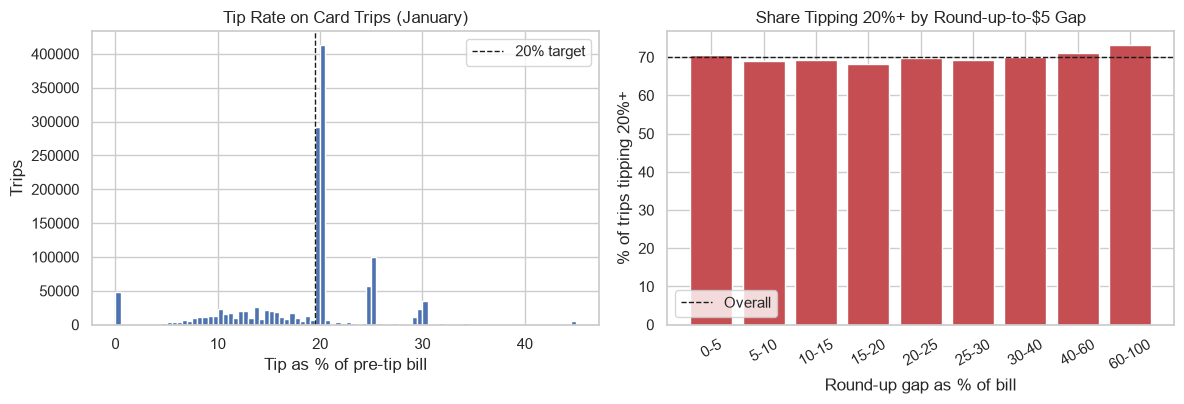

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(jan['tip_rate'].clip(0, 0.45) * 100, bins=90, color='#4C72B0')
axes[0].axvline(19.5, color='k', ls='--', lw=1, label='20% target')
axes[0].set(title='Tip Rate on Card Trips (January)', xlabel='Tip as % of pre-tip bill', ylabel='Trips')
axes[0].legend()
bins = pd.cut(jan['roundup5_rate'] * 100, [0, 5, 10, 15, 20, 25, 30, 40, 60, 100])
share = jan.groupby(bins, observed=True)['high_tip'].mean() * 100
axes[1].bar(range(len(share)), share.values, color='#C44E52')
axes[1].set_xticks(range(len(share))); axes[1].set_xticklabels([f'{int(b.left)}-{int(b.right)}' for b in share.index], rotation=30)
axes[1].axhline(jan['high_tip'].mean() * 100, color='k', ls='--', lw=1, label='Overall')
axes[1].set(title='Share Tipping 20%+ by Round-up-to-$5 Gap', xlabel='Round-up gap as % of bill', ylabel='% of trips tipping 20%+')
axes[1].legend()
save_fig('fig0_bill_rounding')

In [ ]:
D1_NUM = ['trip_distance', 'trip_minutes', 'avg_speed_mph', 'fare_amount', 'extra', 'tolls_amount',
          'passenger_count', 'pickup_hour', 'pickup_dow', 'is_weekend', 'hour_sin', 'hour_cos',
          'pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude',
          'airport_trip', 'manhattan_pickup']
NEW_NUM = ['rush_hour', 'is_night', 'fare_per_mile', 'minutes_per_mile']
BILL = ['pre_tip_bill', 'roundup1_rate', 'roundup2_rate', 'roundup5_rate', 'roundup10_rate', 'roundup20_rate',
        'tip20_floor_rate', 'tip20_ceil_rate', 'bill_cents', 'tip20_cents']
ONEHOT = ['VendorID', 'RatecodeID', 'store_and_fwd_flag']
CELLS = ['pickup_cell', 'dropoff_cell']
FINAL_NUM = D1_NUM + NEW_NUM + BILL
ALL_FEATURES = FINAL_NUM + ONEHOT + CELLS

def make_preprocessor(num_cols, use_cells=True):
    parts = [('num', StandardScaler(), num_cols),
             ('onehot', OneHotEncoder(handle_unknown='ignore'), ONEHOT)]
    if use_cells:
        parts.append(('cells', TargetEncoder(target_type='binary', random_state=RANDOM_STATE), CELLS))
    return ColumnTransformer(parts)

# Split: 60% train, 15% validation (threshold choice), 25% test - all stratified
X, y = jan[ALL_FEATURES], jan['high_tip']
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=RANDOM_STATE)
X_feb, y_feb = feb[ALL_FEATURES], feb['high_tip']
print(f"Train {len(X_train):,} | Validation {len(X_val):,} | Test {len(X_test):,} | Feb out-of-time {len(X_feb):,}")

Train 843,462 | Validation 210,866 | Test 351,443 | Feb out-of-time 374,979


## 4. Reference Models, Feature Ablation and Learning Curve

- **D1 Random Forest**: the Deliverable 1 model (100 trees, depth 20, min leaf 5, D1 features only). To keep Colab run time short it is trained on a 300,000-trip subset of the training set.
- **Feature ablation**: one fixed gradient-boosting setup is trained on the full training set with three feature sets, so the gain from each group is measured on the same test trips.
- **Learning curve**: the full-feature model trained on growing subsets, to check whether more data still helps.

In [ ]:
t = time.time()
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=300_000, stratify=y_train, random_state=RANDOM_STATE)
d1_model = Pipeline([('prep', make_preprocessor(D1_NUM, use_cells=False)),
                     ('clf', RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=5,
                                                    class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))])
d1_model.fit(X_sub, y_sub)
d1_auc = roc_auc_score(y_test, d1_model.predict_proba(X_test)[:, 1])
print(f"D1 Random Forest test ROC-AUC: {d1_auc:.3f}  ({time.time()-t:.0f} s)")

D1 Random Forest test ROC-AUC: 0.575  (11 s)


In [ ]:
ABL_PARAMS = dict(learning_rate=0.1, max_iter=200, max_leaf_nodes=15, min_samples_leaf=200, l2_regularization=1.0)
def hgb_pipe(num_cols, use_cells=True, **params):
    return Pipeline([('prep', make_preprocessor(num_cols, use_cells)),
                     ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE, **params))])

ablation_sets = {'D1 features': (D1_NUM, False),
                 '+ location cells, time/fare ratios (first D2 version)': (D1_NUM + NEW_NUM, True),
                 '+ bill-rounding features (refined)': (FINAL_NUM, True)}
abl_rows = []
for label, (cols, cells) in ablation_sets.items():
    t = time.time()
    m = hgb_pipe(cols, cells, **ABL_PARAMS).fit(X_train, y_train)
    abl_rows.append({'feature_set': label, 'n_features': len(cols) + len(ONEHOT) + (len(CELLS) if cells else 0),
                     'test_auc': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
                     'feb_auc': roc_auc_score(y_feb, m.predict_proba(X_feb)[:, 1]), 'seconds': time.time() - t})
    print(f"{label}: test AUC {abl_rows[-1]['test_auc']:.4f}")
ablation_df = pd.DataFrame(abl_rows).set_index('feature_set')
v1_auc = ablation_df['test_auc'].iloc[1]
ablation_df.round(4)

D1 features: test AUC 0.5875
+ location cells, time/fare ratios (first D2 version): test AUC 0.5882
+ bill-rounding features (refined): test AUC 0.5888


,n_features,test_auc,feb_auc,seconds
feature_set,,,,
D1 features,21,0.5875,0.5852,10.1101
"+ location cells, time/fare ratios (first D2 version)",27,0.5882,0.5865,10.2692
+ bill-rounding features (refined),37,0.5888,0.5870,13.8507


### Leakage check: why the bill is rebuilt from its parts

An early experiment computed the bill as `total_amount - tip_amount`. Mathematically this equals the sum of the charges, but floating-point subtraction leaves residues around 1e-14 that depend on the tip, and the round-up features turn those residues into a signal. The cell below trains the same model on a 200,000-trip subset with both versions. The large jump with the leaky version is not real skill: it disappears once the bill is rebuilt from its parts.

In [ ]:
def bill_features(bill):
    out = {}
    for k in [1, 2, 5, 10, 20]:
        gap = np.ceil(bill / k) * k - bill
        out[f'roundup{k}_rate'] = np.where(gap < 0.01, k, gap) / bill
    out['pre_tip_bill'] = bill
    return pd.DataFrame(out, index=bill.index)

X_lk, _, y_lk, _ = train_test_split(X_train, y_train, train_size=200_000, stratify=y_train, random_state=RANDOM_STATE)
leak_rows = []
for label, src in [('Leaky: total_amount - tip_amount', lambda d: d['total_amount'] - d['tip_amount']),
                   ('Clean: sum of charges, rounded to cents', lambda d: d['pre_tip_bill'])]:
    tr = X_lk.copy(); tr.update(bill_features(src(jan.loc[X_lk.index])))
    te = X_test.copy(); te.update(bill_features(src(jan.loc[X_test.index])))
    m = hgb_pipe(FINAL_NUM, True, **ABL_PARAMS).fit(tr, y_lk)
    leak_rows.append({'bill computed as': label, 'test_auc': roc_auc_score(y_test, m.predict_proba(te)[:, 1])})
leak_df = pd.DataFrame(leak_rows).set_index('bill computed as')
leak_df.round(4)

,test_auc
bill computed as,
Leaky: total_amount - tip_amount,0.7286
"Clean: sum of charges, rounded to cents",0.5824


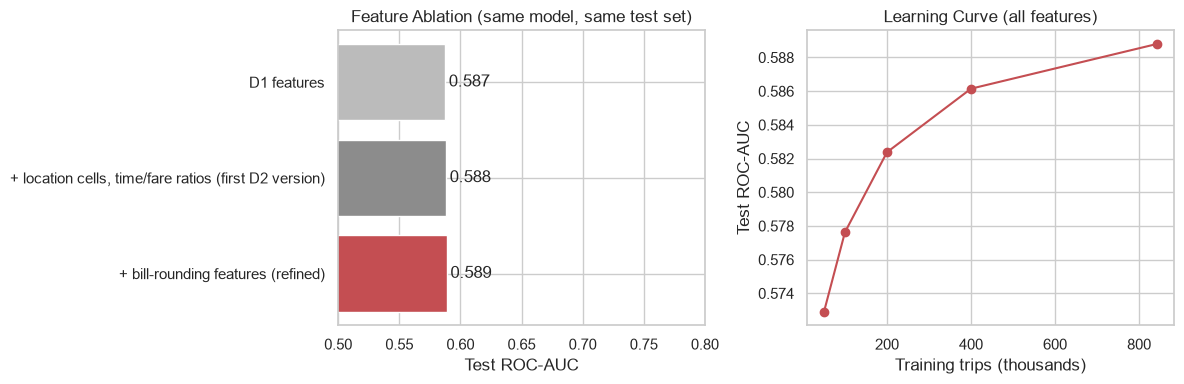

,train_trips,test_auc
0,50000,0.5729
1,100000,0.5776
2,200000,0.5824
3,400000,0.5861
4,843462,0.5888


In [ ]:
lc_rows = []
for n in [50_000, 100_000, 200_000, 400_000, len(X_train)]:
    Xs, ys = (X_train, y_train) if n == len(X_train) else train_test_split(
        X_train, y_train, train_size=n, stratify=y_train, random_state=RANDOM_STATE)[::2]
    m = hgb_pipe(FINAL_NUM, True, **ABL_PARAMS).fit(Xs, ys)
    lc_rows.append({'train_trips': n, 'test_auc': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
lc_df = pd.DataFrame(lc_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(ablation_df.index[::-1], ablation_df['test_auc'][::-1], color=['#C44E52', '#8C8C8C', '#BBBBBB'])
for i, v in enumerate(ablation_df['test_auc'][::-1]): axes[0].text(v + 0.003, i, f'{v:.3f}', va='center')
axes[0].set(xlim=(0.5, 0.8), title='Feature Ablation (same model, same test set)', xlabel='Test ROC-AUC')
axes[1].plot(lc_df['train_trips'] / 1000, lc_df['test_auc'], 'o-', color='#C44E52')
axes[1].set(title='Learning Curve (all features)', xlabel='Training trips (thousands)', ylabel='Test ROC-AUC')
save_fig('fig1a_ablation_learning_curve')
lc_df.round(4)

## 5. Hyperparameter Tuning

Each model family is tuned with `RandomizedSearchCV` (3-fold stratified CV, scoring = ROC-AUC) on a stratified 200,000-trip subset of the training set, using all features. Randomized search covers wide ranges with a fixed budget, which is more efficient than a full grid (Bergstra & Bengio, 2012). The whole pipeline (scaling, encoding, model) is tuned together, so the target encoder is refit inside every fold.

Refinements over the first version: gradient boosting searches larger trees and up to 1,000 boosting rounds with **early stopping** (training stops once a 10% internal validation slice stops improving), feature subsampling (`max_features`) is added, the Random Forest uses row subsampling (`max_samples`) to stay fast, and **no class weights** are used, so predicted probabilities stay calibrated.

In [ ]:
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=200_000, stratify=y_train, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    'Logistic Regression': (
        LogisticRegression(max_iter=3000, solver='lbfgs'),
        {'clf__C': loguniform(1e-3, 1e2)}, 6),
    'Random Forest': (
        RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        {'clf__n_estimators': [100, 200], 'clf__max_depth': [15, 20, 25, None],
         'clf__min_samples_leaf': [20, 50, 100], 'clf__max_features': ['sqrt', 0.3],
         'clf__max_samples': [0.3, 0.5]}, 6),
    'Hist Gradient Boosting': (
        HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                       n_iter_no_change=30, random_state=RANDOM_STATE),
        {'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__max_leaf_nodes': [31, 63, 127, 255],
         'clf__min_samples_leaf': [50, 100, 200, 400], 'clf__l2_regularization': [0.0, 1.0, 10.0],
         'clf__max_features': [0.5, 0.8, 1.0]}, 12),
}

searches, tuning_rows = {}, []
for name, (clf, space, n_iter) in search_spaces.items():
    t = time.time()
    pipe = Pipeline([('prep', make_preprocessor(FINAL_NUM)), ('clf', clf)])
    s = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring='roc_auc', cv=cv,
                           random_state=RANDOM_STATE, n_jobs=1, refit=False)
    s.fit(X_tune, y_tune)
    searches[name] = s
    best = s.best_index_
    tuning_rows.append({'model': name, 'candidates': n_iter,
                        'best_cv_auc': s.cv_results_['mean_test_score'][best],
                        'cv_std': s.cv_results_['std_test_score'][best],
                        'worst_cv_auc': np.nanmin(s.cv_results_['mean_test_score']),
                        'minutes': (time.time() - t) / 60,
                        'best_params': {k.replace('clf__', ''): (round(v, 4) if isinstance(v, float) else v)
                                        for k, v in s.best_params_.items()}})
    print(f"{name}: best CV AUC = {tuning_rows[-1]['best_cv_auc']:.4f}  ({tuning_rows[-1]['minutes']:.1f} min)")
    print("   best params:", tuning_rows[-1]['best_params'])

tuning_df = pd.DataFrame(tuning_rows).set_index('model')
tuning_df.round(4)

Logistic Regression: best CV AUC = 0.5719  (1.8 min)
   best params: {'C': np.float64(0.9847)}
Random Forest: best CV AUC = 0.5792  (1.1 min)
   best params: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_samples': 0.5, 'max_features': 0.3, 'max_depth': None}
Hist Gradient Boosting: best CV AUC = 0.5817  (2.2 min)
   best params: {'min_samples_leaf': 400, 'max_leaf_nodes': 31, 'max_features': 0.5, 'learning_rate': 0.05, 'l2_regularization': 1.0}


,candidates,best_cv_auc,cv_std,worst_cv_auc,minutes,best_params
model,,,,,,
Logistic Regression,6,0.5719,0.0042,0.5674,1.7733,{'C': 0.9847}
Random Forest,6,0.5792,0.0036,0.5758,1.1158,"{'n_estimators': 100, 'min_samples_leaf': 100,..."
Hist Gradient Boosting,12,0.5817,0.0032,0.5712,2.2327,"{'min_samples_leaf': 400, 'max_leaf_nodes': 31..."


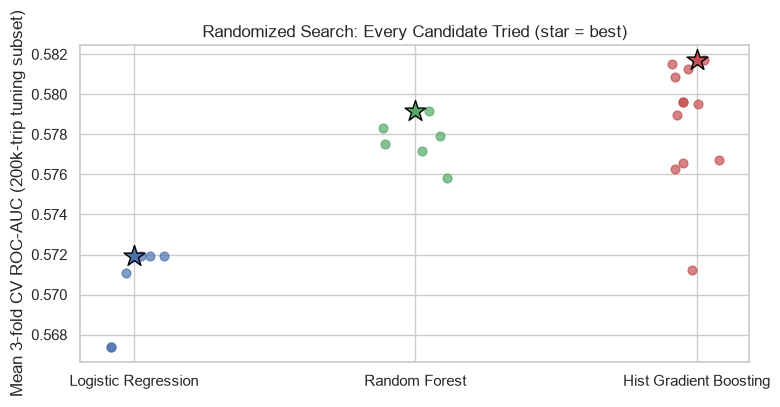

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, s) in enumerate(searches.items()):
    scores = s.cv_results_['mean_test_score']
    ax.scatter(np.full(len(scores), i) + np.random.uniform(-0.12, 0.12, len(scores)), scores,
               color=COLORS[name], alpha=0.7, s=40)
    ax.scatter(i, scores.max(), marker='*', s=250, color=COLORS[name], edgecolor='black', zorder=3)
ax.set_xticks(range(len(searches))); ax.set_xticklabels(searches.keys())
ax.set(ylabel='Mean 3-fold CV ROC-AUC (200k-trip tuning subset)', title='Randomized Search: Every Candidate Tried (star = best)')
save_fig('fig1_tuning_results')

## 6. Final Model Training and Evaluation

The best settings for each family are refit on the **full training set** (about 840,000 trips). All models are then scored on the untouched test set.

In [ ]:
final_models = {}
for name, (clf, _, _) in search_spaces.items():
    t = time.time()
    pipe = Pipeline([('prep', make_preprocessor(FINAL_NUM)), ('clf', clf)])
    pipe.set_params(**searches[name].best_params_)
    pipe.fit(X_train, y_train)
    final_models[name] = pipe
    extra = f", {pipe.named_steps['clf'].n_iter_} boosting rounds" if name == 'Hist Gradient Boosting' else ''
    print(f"{name} refit in {time.time()-t:.0f} s{extra}")

def scores(y_true, p_high, thr_low=0.5):
    # p_high = probability of a 20%+ tip; a trip is flagged 'low tip' when 1 - p_high >= thr_low
    p_low = 1 - p_high
    flag_low = (p_low >= thr_low).astype(int)
    y_low = 1 - np.asarray(y_true)
    return {'roc_auc': roc_auc_score(y_true, p_high),
            'pr_auc_low_tip': average_precision_score(y_low, p_low),
            'accuracy': accuracy_score(y_low, flag_low),
            'precision_low_tip': precision_score(y_low, flag_low, zero_division=0),
            'recall_low_tip': recall_score(y_low, flag_low),
            'f1_low_tip': f1_score(y_low, flag_low),
            'f1_macro': f1_score(y_low, flag_low, average='macro'),
            'balanced_accuracy': balanced_accuracy_score(y_low, flag_low),
            'flag_rate': flag_low.mean(),
            'brier': brier_score_loss(y_true, p_high)}

proba_test = {'D1 Random Forest': d1_model.predict_proba(X_test)[:, 1]}
proba_test.update({n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()})
test_df = pd.DataFrame({n: scores(y_test, p) for n, p in proba_test.items()}).T
test_df.round(3)

Logistic Regression refit in 18 s
Random Forest refit in 38 s
Hist Gradient Boosting refit in 31 s, 692 boosting rounds


,roc_auc,pr_auc_low_tip,accuracy,precision_low_tip,recall_low_tip,f1_low_tip,f1_macro,balanced_accuracy,flag_rate,brier
D1 Random Forest,0.575,0.361,0.595,0.357,0.436,0.393,0.544,0.550,0.367,0.237
Logistic Regression,0.576,0.362,0.700,0.544,0.009,0.017,0.420,0.503,0.005,0.207
Random Forest,0.587,0.372,0.701,0.567,0.007,0.013,0.418,0.502,0.004,0.206
Hist Gradient Boosting,0.592,0.376,0.701,0.564,0.015,0.028,0.426,0.505,0.008,0.205


In [ ]:
best_name = test_df['roc_auc'].drop('D1 Random Forest').idxmax()
best_model = final_models[best_name]
print("Selected final model:", best_name)


X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=200_000, stratify=y_train, random_state=RANDOM_STATE)
cv5 = cross_val_score(best_model, X_cv, y_cv, scoring='roc_auc',
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=1)
print(f"5-fold CV ROC-AUC: {cv5.mean():.3f} +/- {cv5.std():.3f}  (folds: {np.round(cv5, 3)})")

Selected final model: Hist Gradient Boosting
5-fold CV ROC-AUC: 0.584 +/- 0.003  (folds: [0.578 0.586 0.585 0.585 0.584])


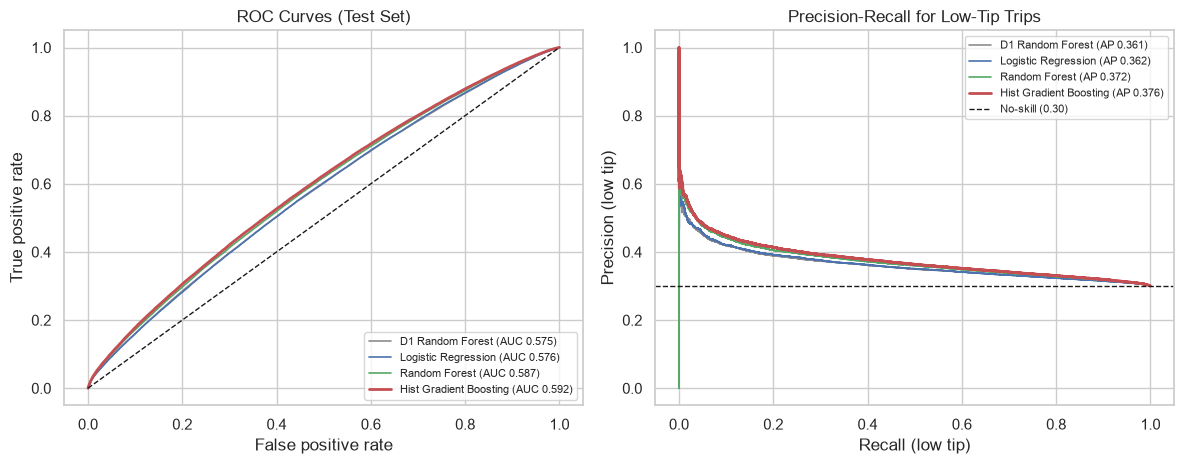

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
y_low_test = 1 - y_test
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=COLORS[name], lw=2 if name == best_name else 1.2,
                 label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_low_test, 1 - p)
    axes[1].plot(rec, prec, color=COLORS[name], lw=2 if name == best_name else 1.2,
                 label=f"{name} (AP {average_precision_score(y_low_test, 1 - p):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(title='ROC Curves (Test Set)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_low_test.mean(), color='k', ls='--', lw=1, label=f'No-skill ({y_low_test.mean():.2f})')
axes[1].set(title='Precision-Recall for Low-Tip Trips', xlabel='Recall (low tip)', ylabel='Precision (low tip)')
for ax in axes: ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'upper right')
save_fig('fig2_roc_pr_curves')

### Decision threshold

With a 70/30 class split, a 0.5 cut-off is arbitrary, so the threshold for flagging a trip as **low tip** is chosen on the **validation set** (never the test set) and then applied unchanged to the test set.

Two rules were compared. Maximizing low-tip **F1** sounds natural, but with a weak signal it pushes the model to flag almost every trip (high recall, useless precision). We therefore choose the threshold that maximizes **balanced accuracy** (Youden's J), which weighs missed low-tip trips and false alarms equally.

F1-optimal threshold: 0.24 (flags 84% of validation trips)
Chosen threshold (max balanced accuracy): 0.30 (flags 49% of validation trips)


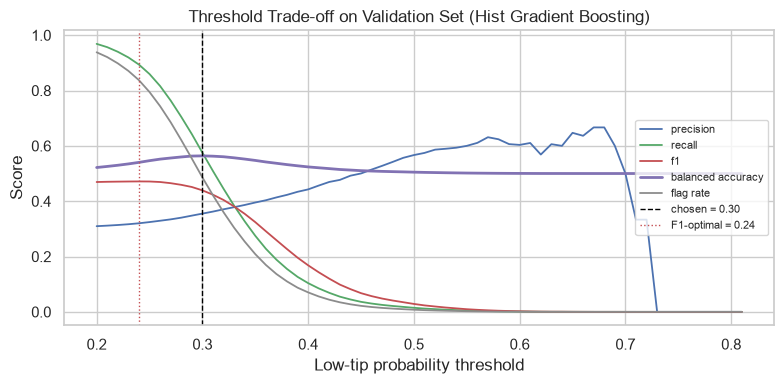

,threshold 0.50,F1-optimal 0.24,chosen 0.30
roc_auc,0.592,0.592,0.592
pr_auc_low_tip,0.376,0.376,0.376
accuracy,0.701,0.399,0.559
precision_low_tip,0.564,0.320,0.355
recall_low_tip,0.015,0.894,0.575
f1_low_tip,0.028,0.472,0.439
f1_macro,0.426,0.388,0.538
balanced_accuracy,0.505,0.540,0.563
flag_rate,0.008,0.837,0.487
brier,0.205,0.205,0.205


In [ ]:
p_val_low = 1 - best_model.predict_proba(X_val)[:, 1]
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
thr_rows = []
for th in thresholds:
    flag = (p_val_low >= th).astype(int)
    thr_rows.append({'threshold': th,
                     'precision': precision_score(1 - y_val, flag, zero_division=0),
                     'recall': recall_score(1 - y_val, flag),
                     'f1': f1_score(1 - y_val, flag),
                     'balanced_accuracy': balanced_accuracy_score(1 - y_val, flag),
                     'flag_rate': flag.mean()})
thr_df = pd.DataFrame(thr_rows)
f1_thr = float(thr_df.loc[thr_df['f1'].idxmax(), 'threshold'])
best_thr = float(thr_df.loc[thr_df['balanced_accuracy'].idxmax(), 'threshold'])
print(f"F1-optimal threshold: {f1_thr:.2f} (flags {thr_df.set_index('threshold').loc[f1_thr, 'flag_rate']:.0%} of validation trips)")
print(f"Chosen threshold (max balanced accuracy): {best_thr:.2f} "
      f"(flags {thr_df.set_index('threshold').loc[best_thr, 'flag_rate']:.0%} of validation trips)")

fig, ax = plt.subplots(figsize=(8, 4))
for col, c in [('precision', '#4C72B0'), ('recall', '#55A868'), ('f1', '#C44E52'),
               ('balanced_accuracy', '#8172B3'), ('flag_rate', '#8C8C8C')]:
    ax.plot(thr_df['threshold'], thr_df[col], label=col.replace('_', ' '), color=c,
            lw=2 if col == 'balanced_accuracy' else 1.3)
ax.axvline(best_thr, color='black', ls='--', lw=1, label=f'chosen = {best_thr:.2f}')
ax.axvline(f1_thr, color='#C44E52', ls=':', lw=1, label=f'F1-optimal = {f1_thr:.2f}')
ax.set(title=f'Threshold Trade-off on Validation Set ({best_name})', xlabel='Low-tip probability threshold', ylabel='Score')
ax.legend(fontsize=8, loc='center right')
save_fig('fig3_threshold_tradeoff')

final_test = scores(y_test, proba_test[best_name], thr_low=best_thr)
default_test = scores(y_test, proba_test[best_name], thr_low=0.5)
f1opt_test = scores(y_test, proba_test[best_name], thr_low=f1_thr)
thr_compare = pd.DataFrame({'threshold 0.50': default_test, f'F1-optimal {f1_thr:.2f}': f1opt_test,
                            f'chosen {best_thr:.2f}': final_test}).round(3)
thr_compare

              precision    recall  f1-score   support

 20% or more      0.752     0.552     0.636    246020
   Below 20%      0.355     0.575     0.439    105423

    accuracy                          0.559    351443
   macro avg      0.553     0.563     0.538    351443
weighted avg      0.633     0.559     0.577    351443



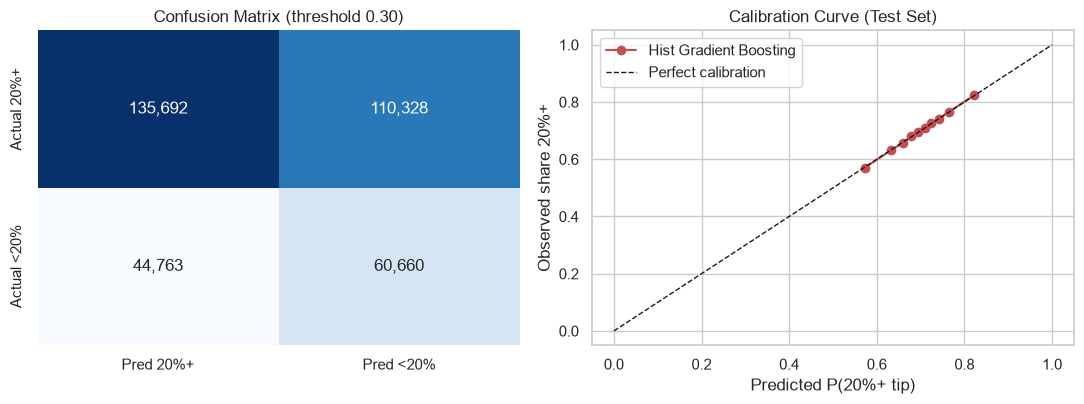

In [ ]:
p_low_test = 1 - proba_test[best_name]
flag_test = (p_low_test >= best_thr).astype(int)
print(classification_report(1 - y_test, flag_test, target_names=['20% or more', 'Below 20%'], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(1 - y_test, flag_test)
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred 20%+', 'Pred <20%'], yticklabels=['Actual 20%+', 'Actual <20%'])
axes[0].set_title(f'Confusion Matrix (threshold {best_thr:.2f})')
frac_pos, mean_pred = calibration_curve(y_test, proba_test[best_name], n_bins=10, strategy='quantile')
axes[1].plot(mean_pred, frac_pos, 'o-', color=COLORS[best_name], label=best_name)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
axes[1].set(title='Calibration Curve (Test Set)', xlabel='Predicted P(20%+ tip)', ylabel='Observed share 20%+')
axes[1].legend()
save_fig('fig4_confusion_calibration')

### Out-of-time check (February 2016)

A model that only works on the month it was trained on has little practical value. The final model, trained only on January, is applied to February trips.

In [ ]:
p_feb = best_model.predict_proba(X_feb)[:, 1]
feb_scores = scores(y_feb, p_feb, thr_low=best_thr)
time_df = pd.DataFrame({'January test (same month)': final_test, 'February (new month)': feb_scores}).T
time_df.round(3)

,roc_auc,pr_auc_low_tip,accuracy,precision_low_tip,recall_low_tip,f1_low_tip,f1_macro,balanced_accuracy,flag_rate,brier
January test (same month),0.592,0.376,0.559,0.355,0.575,0.439,0.538,0.563,0.487,0.205
February (new month),0.590,0.378,0.559,0.355,0.568,0.437,0.537,0.561,0.482,0.206


Permutation importance computed in 28 s


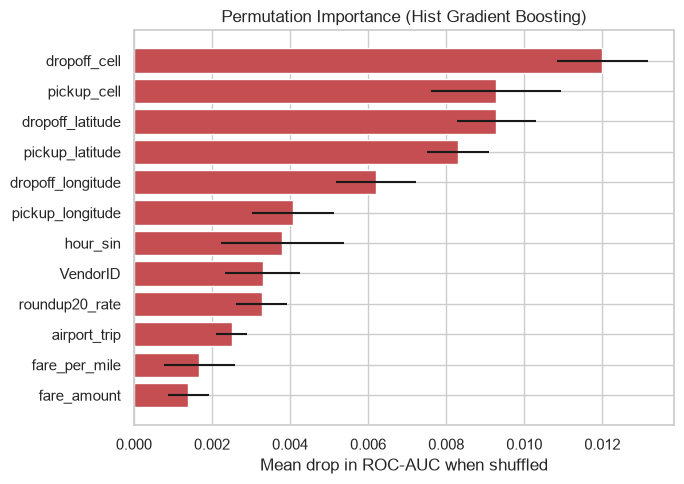

dropoff_cell         0.0120
pickup_cell          0.0093
dropoff_latitude     0.0093
pickup_latitude      0.0083
dropoff_longitude    0.0062
pickup_longitude     0.0041
hour_sin             0.0038
VendorID             0.0033
roundup20_rate       0.0033
airport_trip         0.0025
dtype: float64

In [ ]:
# Permutation importance on a 20,000-trip test sample (drop in ROC-AUC when a feature is shuffled)
X_pi = X_test.sample(20_000, random_state=RANDOM_STATE); y_pi = y_test.loc[X_pi.index]
t = time.time()
pi = permutation_importance(best_model, X_pi, y_pi, scoring='roc_auc', n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=X_pi.columns).sort_values(ascending=False)
perm_std = pd.Series(pi.importances_std, index=X_pi.columns)
print(f"Permutation importance computed in {time.time()-t:.0f} s")

top = perm.head(12)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, xerr=perm_std[top.index], color=COLORS[best_name])
plt.title(f'Permutation Importance ({best_name})'); plt.xlabel('Mean drop in ROC-AUC when shuffled')
save_fig('fig5_permutation_importance')
perm.head(10).round(4)

## 7. Ethical Evaluation: Subgroup Audit

The data has no rider demographics, but trip context can act as a proxy for neighborhood income or rider type. We compare error rates across groups. The key fairness measures are the **flag rate** (share of trips the model labels low-tip) and the **false-flag rate** (share of riders who actually tipped 20%+ but were labelled low-tip). Large gaps would mean the model treats some areas or times unfairly.

In [ ]:
meta = jan.loc[X_test.index]
period = pd.cut(meta['pickup_hour'], [-1, 5, 9, 15, 19, 23], labels=['Night (0-5)', 'Morning (6-9)', 'Midday (10-15)', 'Evening (16-19)', 'Late (20-23)'])
groups = {
    'Pickup area': np.where(meta['manhattan_pickup'] == 1, 'Manhattan core', 'Outside Manhattan core'),
    'Airport': np.where(meta['airport_trip'] == 1, 'Airport trip', 'Non-airport trip'),
    'Day type': np.where(meta['is_weekend'] == 1, 'Weekend', 'Weekday'),
    'Time of day': period.astype(str),
}
y_low = (1 - y_test).values
rows = []
for gname, labels in groups.items():
    for g in pd.unique(labels):
        m = labels == g
        rows.append({'dimension': gname, 'group': g, 'n_test': int(m.sum()),
                     'actual_low_tip_%': 100 * y_low[m].mean(),
                     'flag_rate_%': 100 * flag_test[m].mean(),
                     'recall_low_tip': recall_score(y_low[m], flag_test[m]),
                     'false_flag_rate_%': 100 * flag_test[m][y_low[m] == 0].mean(),
                     'roc_auc': roc_auc_score(1 - y_low[m], 1 - p_low_test[m])})
subgroup_df = pd.DataFrame(rows)
display(subgroup_df.round(3))

gaps = subgroup_df.groupby('dimension').agg(max_flag_gap=('flag_rate_%', lambda s: s.max() - s.min()),
                                            max_false_flag_gap=('false_flag_rate_%', lambda s: s.max() - s.min()),
                                            auc_range=('roc_auc', lambda s: s.max() - s.min()))
print("Largest gaps within each dimension (percentage points / AUC units):")
gaps.round(3)

,dimension,group,n_test,actual_low_tip_%,flag_rate_%,recall_low_tip,false_flag_rate_%,roc_auc
0,Pickup area,Manhattan core,323023,29.865,47.999,0.567,44.300,0.590
1,Pickup area,Outside Manhattan core,28420,31.495,56.087,0.668,51.184,0.613
2,Airport,Non-airport trip,325979,30.014,48.881,0.576,45.126,0.591
3,Airport,Airport trip,25464,29.783,45.731,0.563,41.264,0.606
4,Day type,Weekend,100244,30.389,51.969,0.602,48.366,0.585
5,Day type,Weekday,251199,29.841,47.330,0.564,43.451,0.594
6,Time of day,Late (20-23),77976,29.628,47.279,0.551,43.980,0.580
7,Time of day,Night (0-5),41889,31.206,57.118,0.656,53.264,0.592
8,Time of day,Midday (10-15),97720,28.000,35.809,0.444,32.478,0.591
9,Time of day,Morning (6-9),54712,32.625,63.213,0.730,58.459,0.610


Largest gaps within each dimension (percentage points / AUC units):


,max_flag_gap,max_false_flag_gap,auc_range
dimension,,,
Airport,3.150,3.862,0.015
Day type,4.639,4.914,0.009
Pickup area,8.088,6.884,0.023
Time of day,27.403,25.980,0.031


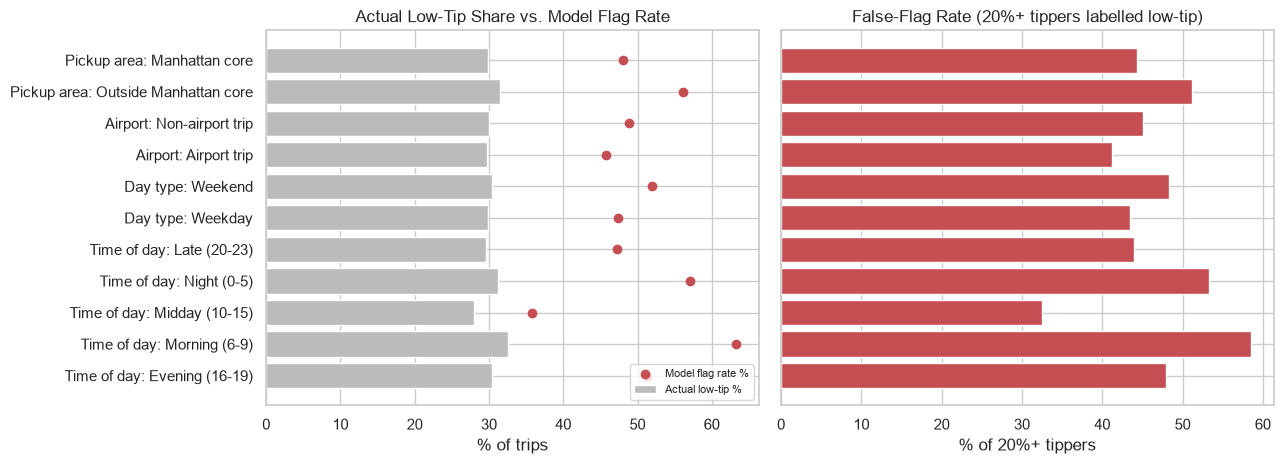

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
plot_df = subgroup_df.assign(label=subgroup_df['dimension'] + ': ' + subgroup_df['group'])
axes[0].barh(plot_df['label'], plot_df['actual_low_tip_%'], color='#BBBBBB', label='Actual low-tip %')
axes[0].scatter(plot_df['flag_rate_%'], plot_df['label'], color=COLORS[best_name], zorder=3, label='Model flag rate %')
axes[0].set(title='Actual Low-Tip Share vs. Model Flag Rate', xlabel='% of trips')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].barh(plot_df['label'], plot_df['false_flag_rate_%'], color=COLORS[best_name])
axes[1].set(title='False-Flag Rate (20%+ tippers labelled low-tip)', xlabel='% of 20%+ tippers')
axes[0].invert_yaxis()
save_fig('fig6_subgroup_audit')

### Ethical considerations
- **Missing population.** Cash trips (about one-third of all trips) have no recorded tip and are excluded. Conclusions describe card riders only.
- **Proxy discrimination.** Pickup and dropoff cells are the strongest features. Location correlates with neighborhood income and race, so any use that steers drivers toward or away from areas could reduce service to outer-borough riders. NYC rules forbid medallion drivers from refusing a passenger, so the model must **never** be shown to drivers before a trip is accepted.
- **Privacy.** Trip GPS points and times can re-identify people. Location is coarsened to ~1 km cells, and only aggregated outputs should leave the analytics team.
- **Transparency.** Permutation importance and the subgroup table are published with the model; predictions are probabilities, not judgements about individual riders.

## 8. Real-World Application: Lift and Revenue Analysis

**Use case:** a fleet operator or the TLC wants to test payment-screen changes (for example, clearer tip buttons or a reminder of the driver's name) on trips most likely to end below 20%. The model ranks trips by low-tip probability; the question is how much better that targeting is than picking trips at random.

**Tip shortfall** = the extra amount a low-tip trip would need to reach 20% of the pre-tip charge.

In [ ]:
ev = jan.loc[X_test.index, ['tip_amount', 'pre_tip_total']].copy()
ev['p_low'] = p_low_test
ev['is_low'] = 1 - y_test.values
ev['shortfall'] = np.where(ev['is_low'] == 1, (0.20 * ev['pre_tip_total'] - ev['tip_amount']).clip(lower=0), 0)
ev['decile'] = pd.qcut(ev['p_low'].rank(method='first', ascending=False), 10, labels=range(1, 11))

base_rate = ev['is_low'].mean()
lift_df = ev.groupby('decile', observed=True).agg(trips=('is_low', 'size'), low_tip_rate=('is_low', 'mean'),
                                                  avg_tip=('tip_amount', 'mean'), shortfall_sum=('shortfall', 'sum'))
lift_df['lift'] = lift_df['low_tip_rate'] / base_rate
lift_df['cum_share_of_low_tip_trips'] = ev.groupby('decile', observed=True)['is_low'].sum().cumsum() / ev['is_low'].sum()
lift_df['cum_share_of_shortfall'] = lift_df['shortfall_sum'].cumsum() / ev['shortfall'].sum()
print(f"Base low-tip rate: {base_rate:.3f} | total shortfall in test set: ${ev['shortfall'].sum():,.0f} "
      f"(avg ${ev.loc[ev.is_low==1, 'shortfall'].mean():.2f} per low-tip trip)")
lift_df.round(3)

Base low-tip rate: 0.300 | total shortfall in test set: $147,089 (avg $1.40 per low-tip trip)


,trips,low_tip_rate,avg_tip,shortfall_sum,lift,cum_share_of_low_tip_trips,cum_share_of_shortfall
decile,,,,,,,
1,35145,0.430,3.728,36245.094,1.433,0.143,0.246
2,35144,0.368,3.143,21574.128,1.225,0.266,0.393
3,35144,0.344,2.819,17075.278,1.146,0.380,0.509
4,35144,0.320,2.570,14089.942,1.068,0.487,0.605
5,35145,0.303,2.393,12034.812,1.011,0.588,0.687
6,35144,0.291,2.276,10605.704,0.970,0.685,0.759
7,35144,0.273,2.244,9826.162,0.911,0.776,0.826
8,35144,0.259,2.255,9297.232,0.863,0.863,0.889
9,35144,0.235,2.459,8966.756,0.782,0.941,0.950


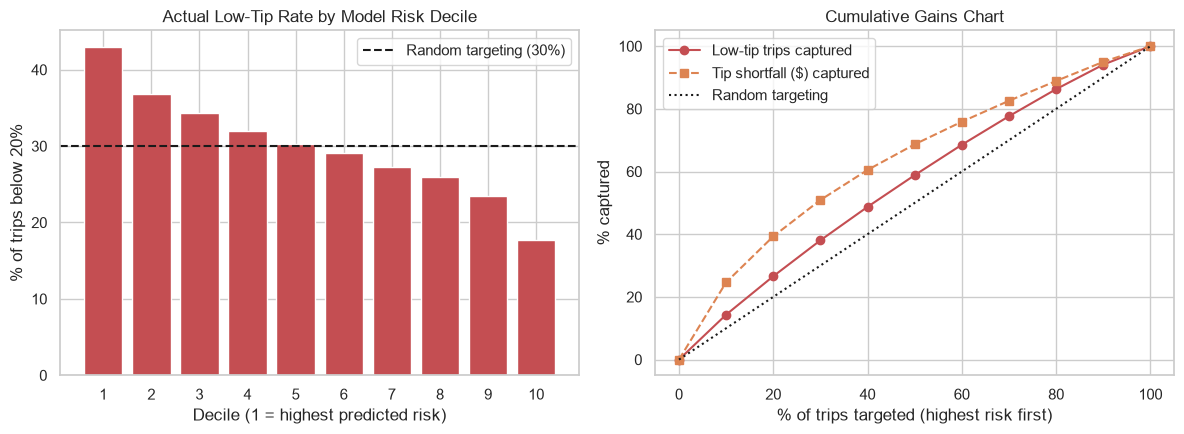

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(lift_df.index.astype(int), lift_df['low_tip_rate'] * 100, color=COLORS[best_name])
axes[0].axhline(base_rate * 100, color='k', ls='--', label=f'Random targeting ({base_rate:.0%})')
axes[0].set(title='Actual Low-Tip Rate by Model Risk Decile', xlabel='Decile (1 = highest predicted risk)', ylabel='% of trips below 20%')
axes[0].set_xticks(range(1, 11)); axes[0].legend()
x = np.r_[0, np.arange(1, 11) * 10]
axes[1].plot(x, np.r_[0, lift_df['cum_share_of_low_tip_trips'] * 100], 'o-', color=COLORS[best_name], label='Low-tip trips captured')
axes[1].plot(x, np.r_[0, lift_df['cum_share_of_shortfall'] * 100], 's--', color='#DD8452', label='Tip shortfall ($) captured')
axes[1].plot([0, 100], [0, 100], 'k:', label='Random targeting')
axes[1].set(title='Cumulative Gains Chart', xlabel='% of trips targeted (highest risk first)', ylabel='% captured')
axes[1].legend()
save_fig('fig7_lift_gains')


 **Repository:** [https://github.com/varunrm/New-York-ML-project](https://github.com/varunrm/New-York-ML-project). Work happened on feature branches with pull-request review; `RANDOM_STATE = 42` keeps every result reproducible.